# HMP Analyses 

Start by importing libraries and reading in the epoched data.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

import mne
from mne.preprocessing import ICA
from mne.io import read_info
warnings.filterwarnings('ignore', category=RuntimeWarning)
import hmp
from hmp import io
from hmp import utils
# from hmp.models import EventModel
import config
# MNE prints a lot by default. This keeps the notebook readable.
mne.set_log_level("WARNING")

print(f"MNE version: {mne.__version__}")

MNE version: 1.13.2


In [2]:
# read in the epoched data

SUBJECTS = ["p1", "p2", "p3", "p4", "p5", "p6", "p7", "p8", "p9", "p10", "p11", "p12", "p13", "p14", "p15", "p16", "p17", "p18", "p19", "p20", "p21", "p22"]
SFREQ = 512 # sampling frequency from Tommy's preprocessing
CPUS = 8 # parallel CPU cores

# check for each epoch file and compile a combined metadata file
full_metadata = []

for subj in SUBJECTS:
    epo_path = os.path.join("./epoched_data", f"{subj}-epo.fif")
    if not os.path.exists(epo_path):
        print(f"WARNING: no epoch file found for {subj}")
        continue
    epochs = mne.read_epochs(epo_path, preload=False, verbose=False)
    if epochs.metadata is None:
        raise ValueError(f"No metadata found in {epo_path} — expected a metadata DataFrame attached to the Epochs object.")
    df = epochs.metadata.copy()
    df['subject'] = subj
    full_metadata.append(df)

full_metadata = pd.concat(full_metadata, ignore_index=True)

print(f"Total trials: {len(full_metadata)}")
print(f"Per subject: {full_metadata.groupby('subject').size().to_dict()}")
print("\nTrials per trial type:")
print(full_metadata.groupby('event_name').size())
print(full_metadata.groupby('first_response').size())


Total trials: 11736
Per subject: {'p1': 521, 'p10': 562, 'p11': 527, 'p12': 496, 'p13': 557, 'p14': 553, 'p15': 561, 'p16': 540, 'p17': 545, 'p18': 556, 'p19': 519, 'p2': 445, 'p20': 551, 'p21': 526, 'p22': 514, 'p3': 549, 'p4': 512, 'p5': 557, 'p6': 532, 'p7': 543, 'p8': 546, 'p9': 524}

Trials per trial type:
event_name
stimulus/irregD1_2    1473
stimulus/irregD1_3     743
stimulus/irregD2_4     731
stimulus/regD1        1473
stimulus/regD2         734
stimulus/regD3         745
stimulus/unordD1_2    2912
stimulus/unordD1_3    1460
stimulus/unordD2_4    1465
dtype: int64
first_response
corr_decomp      4764
corr_other        190
corr_retr        6216
incorr_decomp     194
incorr_other      175
incorr_retr       197
dtype: int64


## Look at the data structure

Columns first_stimulus and first_response are useful. Will need to regroup trials to align with new consecutive/non-consecutive groupings. 

In [3]:
# assert isinstance(p1.metadata, pd.DataFrame)
# p1.metadata
full_metadata

,event_name,stimulus/regD1,stimulus/regD2,stimulus/regD3,stimulus/irregD1_2,stimulus/irregD1_3,stimulus/irregD2_4,stimulus/unordD1_2,stimulus/unordD1_3,stimulus/unordD2_4,...,response/incorr_other,response/corr_retr,response/corr_decomp,response/corr_other,stimulus,response,first_stimulus,first_response,trial_number,subject
0,stimulus/regD2,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,None,NaN,0.849609,NaN,0.0,0.849609,regD2,corr_decomp,1,p1
1,stimulus/unordD2_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,...,None,0.607422,NaN,NaN,0.0,0.607422,unordD2_4,corr_retr,3,p1
2,stimulus/regD1,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,None,0.960938,NaN,NaN,0.0,0.960938,regD1,corr_retr,4,p1
3,stimulus/regD2,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,None,NaN,1.205078,NaN,0.0,1.205078,regD2,corr_decomp,5,p1
4,stimulus/regD3,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN,NaN,...,None,1.095703,NaN,NaN,0.0,1.095703,regD3,corr_retr,6,p1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11731,stimulus/unordD1_2,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,...,None,0.802734,NaN,None,0.0,0.802734,unordD1_2,corr_retr,572,p22
11732,stimulus/unordD1_3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,...,None,0.683594,NaN,None,0.0,0.683594,unordD1_3,corr_retr,573,p22
11733,stimulus/unordD1_2,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,...,None,0.876953,NaN,None,0.0,0.876953,unordD1_2,corr_retr,574,p22
11734,stimulus/unordD2_4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,...,None,0.634766,NaN,None,0.0,0.634766,unordD2_4,corr_retr,575,p22


## Filter Data 
Remove incorrect trials since they are not of interest.  

In [4]:
# create a list of paths to the epoched_data
subj_files = []
for subj in SUBJECTS:
    path = os.path.join("./epoched_data", f"{subj}-epo.fif")
    subj_files.append(path)

# read the epoched data files
epoch_data, info = hmp.io.read_mne_epochs(
    recordings = subj_files,
    subj_name = SUBJECTS,
    montage = "biosemi64",
    preprocessing_kwargs = dict(highpass=0.5, lowpass=40, sfreq=SFREQ, pick_channels="eeg"),
    cpus = CPUS,
    verbose = True,
)

Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p4-epo.fif ...
Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p8-epo.fif ...
Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p7-epo.fif ...
Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p3-epo.fif ...
Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p5-epo.fif ...
Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p1-epo.fif ...
    Found the data of interest:
        t =    -250.00 ...    2964.84 ms
        0 CTF compensation matrices available
    Found the data of interest:
        t =    -250.00 ...    2361.33 m

/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (801), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)


Adding metadata with 21 columns
521 matching events found
No baseline correction applied
0 projection items activated
Adding metadata with 21 columns
546 matching events found
No baseline correction applied
0 projection items activated
Adding metadata with 21 columns
543 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 1 to achieve a sampling frequency of 512.0Hz
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 3381 samples (6.604 s)

Adding metadata with 21 columns
557 matching eve

/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1189), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)
/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1338), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)
/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1437), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)


Epoch data will be decimated by 1 to achieve a sampling frequency of 512.0Hz
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 3381 samples (6.604 s)

Epoch data will be decimated by 1 to achieve a sampling frequency of 512.0Hz
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition band

/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1491), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)
/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1555), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)
/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1647), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)
/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filte

... (24 outputs left out)

Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p21-epo.fif ...
    Found the data of interest:
        t =    -250.00 ...    2681.64 ms
        0 CTF compensation matrices available
Adding metadata with 21 columns
526 matching events found
No baseline correction applied
0 projection items activated


/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1502), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)


Processing dataset 
Reading /Users/charlielacker/Desktop/SCHOOL/Internship/EXP Order/EEG_OrderVerification/epoched_data/p22-epo.fif ...
Epoch data will be decimated by 1 to achieve a sampling frequency of 512.0Hz
Setting up band-pass filter from 0.5 - 40 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 0.50
- Lower transition bandwidth: 0.50 Hz (-6 dB cutoff frequency: 0.25 Hz)
- Upper passband edge: 40.00 Hz
- Upper transition bandwidth: 10.00 Hz (-6 dB cutoff frequency: 45.00 Hz)
- Filter length: 3381 samples (6.604 s)

    Found the data of interest:
        t =    -250.00 ...    1943.36 ms
        0 CTF compensation matrices available
Adding metadata with 21 columns
514 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated 

/opt/anaconda3/lib/python3.14/site-packages/hmp/io/preprocessing.py:116: RuntimeWarning: filter_length (3381) is longer than the signal (1124), distortion is likely. Reduce filter length or filter a longer signal.
  data.filter(l_freq=preprocessing_kwargs['highpass'], h_freq=lowpass, verbose=verbose)


In [5]:
epoch_data

<xarray.Dataset> Size: 8GB
Dimensions:                 (recording: 22, epoch: 562, channel: 64,
                             sample: 2681)
Coordinates: (12/26)
  * recording               (recording) <U1 88B '' '' '' '' '' ... '' '' '' ''
    subject                 (recording) <U3 264B 'p1' 'p2' 'p3' ... 'p21' 'p22'
  * epoch                   (epoch) int64 4kB 0 1 2 3 4 ... 557 558 559 560 561
    event_name              (recording, epoch) object 99kB 'stimulus/regD2' ....
    stimulus/regD1          (recording, epoch) float64 99kB nan nan ... nan nan
    stimulus/regD2          (recording, epoch) float64 99kB 0.0 nan ... nan nan
    ...                      ...
    response                (recording, epoch) float64 99kB 0.8496 ... nan
    first_stimulus          (recording, epoch) object 99kB 'regD2' ... nan
    first_response          (recording, epoch) object 99kB 'corr_decomp' ... nan
    trial_number            (recording, epoch) float64 99kB 1.0 3.0 ... nan nan
  * channel                 (channel) <U3 768B 'Fp1' 'AF7' 'AF3' ... 'PO4' 'O2'
  * sample                  (sample) int64 21kB -128 -127 -126 ... 2551 2552
Data variables:
    data                    (recording, epoch, channel, sample) float32 8GB -...
Attributes:
    highpass:       0.5
    lowpass:        40.0
    sfreq:          512.0
    pick_channels:  eeg
    reference:      None

In [ ]:
# new coordinate to indicate correctness
epoch_data['first_response'] = epoch_data['first_response'].astype("str")
is_incorr = epoch_data.first_response.str.contains("incorr")
epoch_data = epoch_data.assign_coords({'is_incorr':(('recording', 'epoch'), is_incorr.data)})

# remove incorrect trials
n_before = int(epoch_data.data.isel(sample=0, channel=0).count()) # number of trials before removing any
epoch_data = epoch_data.where(epoch_data.is_incorr == False, drop=True)
n_after = int(epoch_data.data.isel(sample=0, channel=0).count())
n_removed = n_before - n_after
print(f"Removed {n_removed}/{n_before} incorrect trials. "
    f"({n_removed / n_before:.1%}). {n_after} trials retained.")

print(epoch_data)

Removed 566/11736 incorrect trials. (4.8%). 11170 trials retained.
<xarray.Dataset> Size: 8GB
Dimensions:                 (recording: 22, epoch: 562, channel: 64,
                             sample: 2681)
Coordinates: (12/27)
  * recording               (recording) <U1 88B '' '' '' '' '' ... '' '' '' ''
    subject                 (recording) <U3 264B 'p1' 'p2' 'p3' ... 'p21' 'p22'
  * epoch                   (epoch) int64 4kB 0 1 2 3 4 ... 557 558 559 560 561
    event_name              (recording, epoch) object 99kB 'stimulus/regD2' ....
    stimulus/regD1          (recording, epoch) float64 99kB nan nan ... nan nan
    stimulus/regD2          (recording, epoch) float64 99kB 0.0 nan ... nan nan
    ...                      ...
    first_stimulus          (recording, epoch) object 99kB 'regD2' ... nan
    first_response          (recording, epoch) <U13 643kB 'corr_decomp' ... '...
    trial_number            (recording, epoch) float64 99kB 1.0 3.0 ... nan nan
    is_incorr           

In [8]:
# clean variable and coordinate names 
rename_dict = {
    name: name.replace("/", "_")
    for name in list(epoch_data.variables)
    if "/" in name
}
epoch_data = epoch_data.rename(rename_dict)

# save to avoid rereading all files
config.hmp_path.mkdir(parents=True, exist_ok=True)
epoch_data.to_netcdf(config.hmp_path / "epoch_data.nc")
info.save(os.path.join(config.hmp_path, 'info.fif'), overwrite=True)

## Set Parameters for HMP Models
Set min and max RT, PCA components, etc... 

In [38]:
from hmp.basedata import PCA, from_io
base_data = from_io(epoch_data)
base_data.crop_reject_epochs(
    duration_id="response", # Select variable that holds reaction time information
    min_duration=0.4, # Minimum RT
    max_duration=3, # Maximum RT
    offsets=0.25, # Pad min/max to account for crosscorrelation, not included in data after
)

# unstack MultiIndex item
base_data.data = base_data.data.reset_index("trial")
base_data.data = base_data.data.assign_coords(trial=range(base_data.data.sizes["trial"]))

pca=PCA(n_comp=0.99) # PCA that accounts for 99% of variance
base_data.project(pca)
print("Total components available:", base_data.data.sizes["component"])

base_data.apply_variance_ops(whiten=True) # All components will have unit variance

# restack MultiIndex 
base_data.data = base_data.data.set_index(trial=["recording", "epoch"])

Found 11170 trials with positively defined durations and 0 trials without durations (0 or nan)

Rejection summary: 
 0 trials rejected based on threshold of inf 
 58 trials rejected  based on duration limit of (0.4, 3) 
 0 with duration but without data (nan at time 0)
14 components retained, explaining 0.99091% variance
Total components available: 14


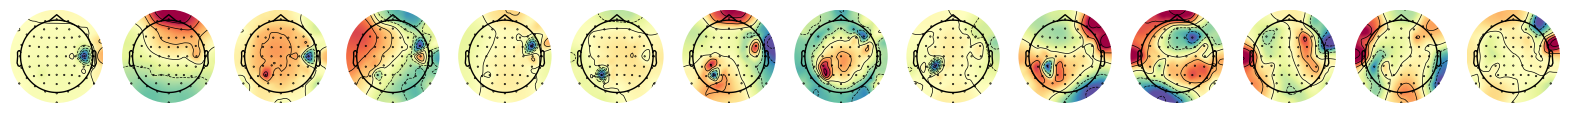

In [42]:
# plot source localization of the PCA
from hmp.visu import plot_components_sensor
plt.rcParams['figure.figsize'] = [20, 10]

plot_components_sensor(base_data.projector.weights, info)
plt.show()